In [ ]:
# Recarregar ficheiros Python externos automaticamente
%load_ext autoreload
%autoreload 2

import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Configurações visuais
sns.set_theme(style="darkgrid")
plt.rcParams['figure.figsize'] = (14, 7)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
ticker = 'DIS'
start_date = '1985-01-01'
end_date = '2025-12-31'

print(f"Baixando dados de {ticker}...")
df = yf.download(ticker, start=start_date, end=end_date, group_by="ticker", auto_adjust=True)
display(df.head())
print(df[ticker].columns)
display(df[ticker])
df = df[ticker]
display(df.head())

Baixando dados de DIS...


[*********************100%***********************]  1 of 1 completed


Ticker           DIS                                        
Price           Open      High       Low     Close    Volume
Date                                                        
1985-01-02  0.852110  0.855661  0.852110  0.853886   1707856
1985-01-03  0.852110  0.852110  0.845009  0.846784  11901470
1985-01-04  0.845009  0.845009  0.841459  0.843234   3323264
1985-01-07  0.846785  0.859211  0.846785  0.853886   3381652
1985-01-08  0.853886  0.860987  0.850336  0.859212   2997263

Index(['Open', 'High', 'Low', 'Close', 'Volume'], dtype='str', name='Price')


Price,Open,High,Low,Close,Volume
Date,,,,,
1985-01-02,0.852110,0.855661,0.852110,0.853886,1707856
1985-01-03,0.852110,0.852110,0.845009,0.846784,11901470
1985-01-04,0.845009,0.845009,0.841459,0.843234,3323264
1985-01-07,0.846785,0.859211,0.846785,0.853886,3381652
1985-01-08,0.853886,0.860987,0.850336,0.859212,2997263
...,...,...,...,...,...
2025-12-23,112.290001,113.309998,112.040001,113.220001,7634500
2025-12-24,112.940002,114.529999,112.800003,114.480003,4606700
2025-12-26,114.150002,114.739998,113.269997,113.559998,5428900


Price,Open,High,Low,Close,Volume
Date,,,,,
1985-01-02,0.852110,0.855661,0.852110,0.853886,1707856
1985-01-03,0.852110,0.852110,0.845009,0.846784,11901470
1985-01-04,0.845009,0.845009,0.841459,0.843234,3323264
1985-01-07,0.846785,0.859211,0.846785,0.853886,3381652
1985-01-08,0.853886,0.860987,0.850336,0.859212,2997263


In [32]:
df.reset_index(inplace=True)
df.columns = ['_'.join(col).strip() if isinstance(col, tuple) else col for col in df.columns]
df.columns = [col.replace('_', '') if col.endswith('_') else col for col in df.columns]
df['Date'] = pd.to_datetime(df['Date']).dt.tz_localize(None)

display(df.tail())
display(df.info())

,index,Date,Open,High,Low,Close,Volume
10324,10324,2025-12-23,112.290001,113.309998,112.040001,113.220001,7634500
10325,10325,2025-12-24,112.940002,114.529999,112.800003,114.480003,4606700
10326,10326,2025-12-26,114.150002,114.739998,113.269997,113.559998,5428900
10327,10327,2025-12-29,113.320000,114.489998,113.309998,114.190002,7966000
10328,10328,2025-12-30,114.099998,115.279999,114.099998,114.790001,6883900


<class 'pandas.DataFrame'>
RangeIndex: 10329 entries, 0 to 10328
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype        
---  ------  --------------  -----        
 0   index   10329 non-null  int64        
 1   Date    10329 non-null  datetime64[s]
 2   Open    10329 non-null  float64      
 3   High    10329 non-null  float64      
 4   Low     10329 non-null  float64      
 5   Close   10329 non-null  float64      
 6   Volume  10329 non-null  int64        
dtypes: datetime64[s](1), float64(4), int64(2)
memory usage: 565.0 KB


None

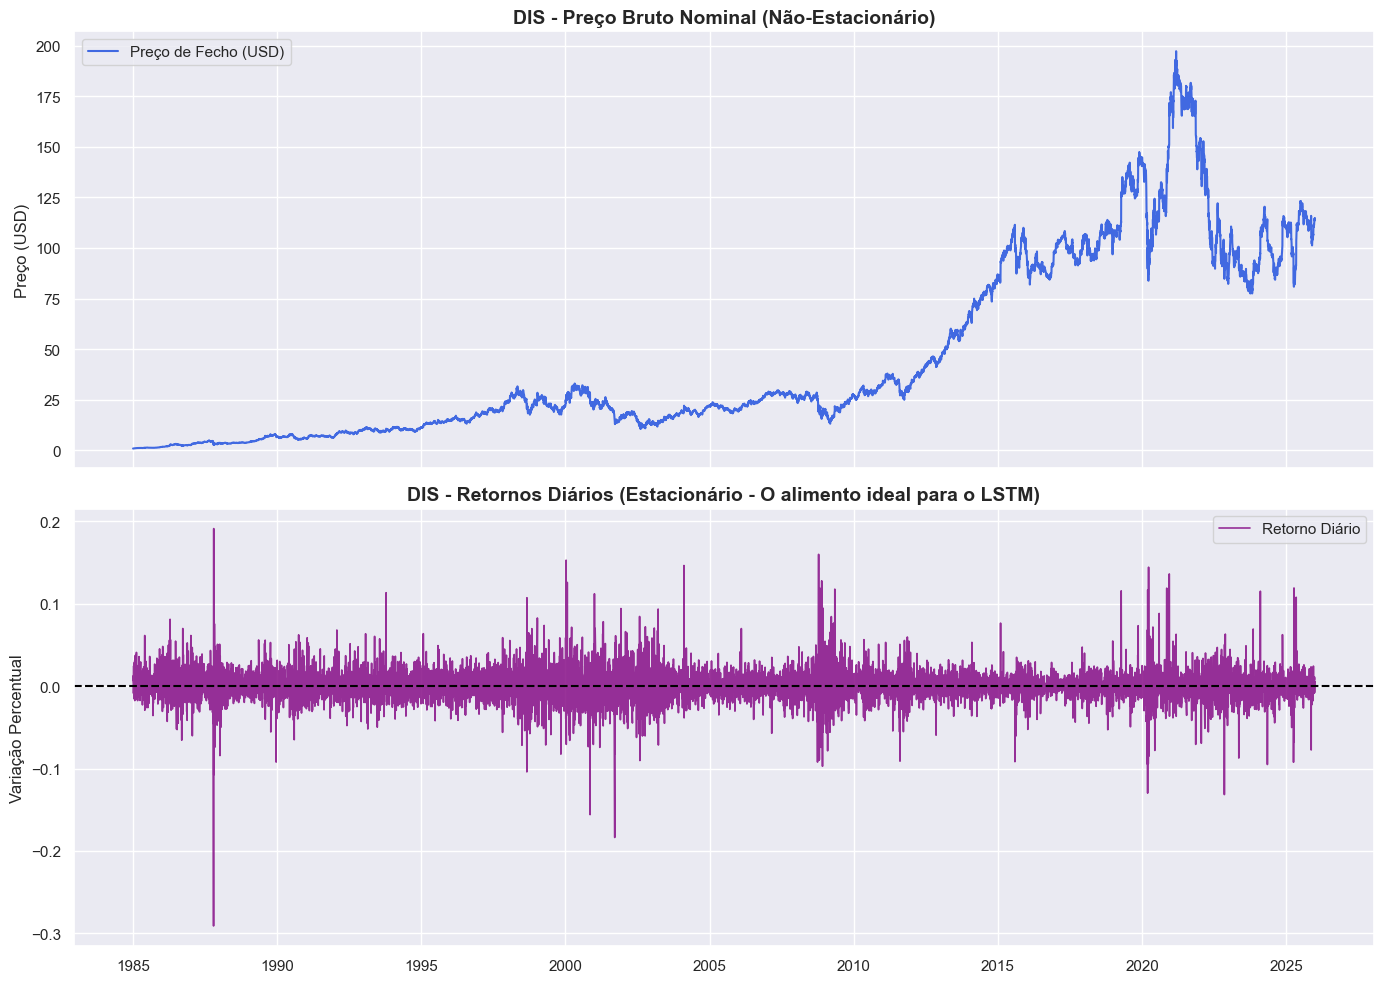

In [ ]:
# Criando "Feature" matemática: O Retorno Diário
df['Daily_Return'] = df['Close'].pct_change()

# Plotando os dois gráficos lado a lado para comparação
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Gráfico 1: O Preço Bruto Nominal
axes[0].plot(df['Date'], df['Close'], color='royalblue', linewidth=1.5, label='Preço de Fecho (USD)')
axes[0].set_title(f'{ticker} - Preço Bruto Nominal (Não-Estacionário)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Preço (USD)')
axes[0].legend()

# Gráfico 2: O Retorno Diário Percentual
axes[1].plot(df['Date'], df['Daily_Return'], color='purple', linewidth=1.2, label='Retorno Diário', alpha=0.8)
axes[1].axhline(0, color='black', linestyle='--', linewidth=1.5) # Linha zero
axes[1].set_title(f'{ticker} - Retornos Diários (Estacionário - ideal para o modelo LSTM)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Variação Percentual')
axes[1].legend()

plt.tight_layout()
plt.show()

In [34]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# 1. Isolamos as nossas features (O Retorno Diário que já calculámos na Célula 3)
# Vamos usar apenas o Retorno Diário para esta V1 (Manter a simplicidade para o baseline)
dados_ml = df[['Date', 'Daily_Return']].dropna().copy()
dados_ml.set_index('Date', inplace=True)

# 2. Normalização (StandardScaler)
scaler = StandardScaler()
dados_escalados = scaler.fit_transform(dados_ml)

print(f"Formato dos dados escalados: {dados_escalados.shape}")

Formato dos dados escalados: (10328, 1)


In [ ]:
def create_sequences(data, time_steps=30):
    """
    Transforma uma série temporal num formato 3D supervisionado para o LSTM.
    X: [Amostras, Passos_Temporais, Features]
    y: [Amostras, 1] (O alvo a prever)
    """
    X, y = [], []
    for i in range(len(data) - time_steps):
        # Pega em 30 dias de dados
        X.append(data[i:(i + time_steps)])
        # O alvo é o retorno do dia imediatamente a seguir
        y.append(data[i + time_steps, 0])

    return np.array(X), np.array(y)

TIME_STEPS = 30

X, y = create_sequences(dados_escalados, time_steps=TIME_STEPS)
print(f"Formato de X (Entrada LSTM): {X.shape} -> (Amostras, Dias, Features)")
print(f"Formato de y (Alvo): {y.shape}")

# Divisão em Treino (80%) e Teste (20%) - sem randomização (shuffle=False) por ser série temporal
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

Formato de X (Entrada LSTM): (10298, 30, 1) -> (Amostras, Dias, Features)
Formato de y (Alvo): (10298,)


In [36]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# 1. Definição do Modelo
model = Sequential([
    # A camada LSTM recebe (Passos_Temporais, Número_de_Features)
    LSTM(64, activation='tanh', input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2), # Desliga 20% dos neurónios aleatoriamente para evitar overfitting
    Dense(1) # Camada de saída: 1 único valor contínuo (A previsão do retorno de amanhã)
])

# 2. Compilação
model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
model.summary()

# 3. Treino
print("Iniciando o treino do V1 do modelo...")
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1, # Usa 10% do treino para validação interna
    shuffle=False, # Nunca embaralhar séries temporais durante o fit
    verbose=1
)

e:\OneDrive\NewEra\Automation\FIAP\MLET\Fase4\projects\fiap-ml-stock-price-prediction\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

Iniciando o treino do V1 do modelo...
Epoch 1/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 21s 20ms/step - loss: 1.0683 - val_loss: 0.3604
Epoch 2/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 1.0652 - val_loss: 0.3609
Epoch 3/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 1.0641 - val_loss: 0.3616
Epoch 4/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 1.0633 - val_loss: 0.3615
Epoch 5/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 1.0624 - val_loss: 0.3620
Epoch 6/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 1.0609 - val_loss: 0.3616
Epoch 7/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 1.0617 - val_loss: 0.3618
Epoch 8/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 1.0616 - val_loss: 0.3618
Epoch 9/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 1.0575 - val_loss: 0.3617
Epoch 10/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 1.0543 - val_loss: 0.3629
Epoch 11/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 1.0561 - val_loss: 0.3617
Ep

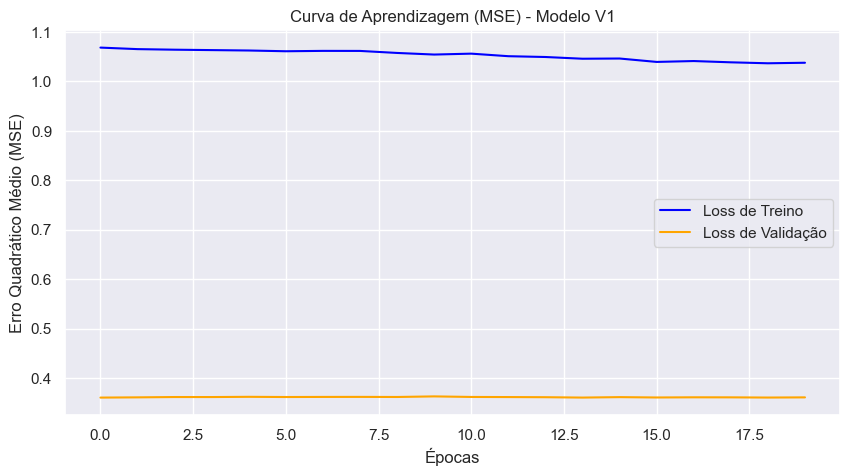

In [37]:
# Gráfico da curva de Loss (Perda)
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Loss de Treino', color='blue')
plt.plot(history.history['val_loss'], label='Loss de Validação', color='orange')
plt.title('Curva de Aprendizagem (MSE) - Modelo V1')
plt.xlabel('Épocas')
plt.ylabel('Erro Quadrático Médio (MSE)')
plt.legend()
plt.show()

In [ ]:
from statsmodels.tsa.stattools import adfuller

def testar_estacionariedade(serie, nome_serie):
    """
    Executa o Teste Augmented Dickey-Fuller (ADF) para verificar se a série é estacionária.
    """
    print(f"--- Teste Dickey-Fuller Aumentado (ADF) para: {nome_serie} ---")

    # Removemos os NaNs (valores nulos) que o cálculo de retornos possa ter gerado
    resultado = adfuller(serie.dropna())

    print(f'Estatística ADF: {resultado[0]:.4f}')
    print(f'Valor-p (p-value): {resultado[1]:.4f}')

    # A regra de ouro da estatística: se p < 0.05, é estacionária!
    if resultado[1] <= 0.05:
        print("A série é ESTACIONÁRIA.")
    else:
        print("A série é NÃO-ESTACIONÁRIA.")

# Executar os testes
testar_estacionariedade(df['Close'], 'Preço Bruto (Close)')
print("\n")
testar_estacionariedade(df['Daily_Return'], 'Retorno Diário (Daily_Return)')

--- Teste Dickey-Fuller Aumentado (ADF) para: Preço Bruto (Close) ---
Estatística ADF: -1.0566
Valor-p (p-value): 0.7320
A série é NÃO-ESTACIONÁRIA.


--- Teste Dickey-Fuller Aumentado (ADF) para: Retorno Diário (Daily_Return) ---
Estatística ADF: -75.7283
Valor-p (p-value): 0.0000
A série é ESTACIONÁRIA.


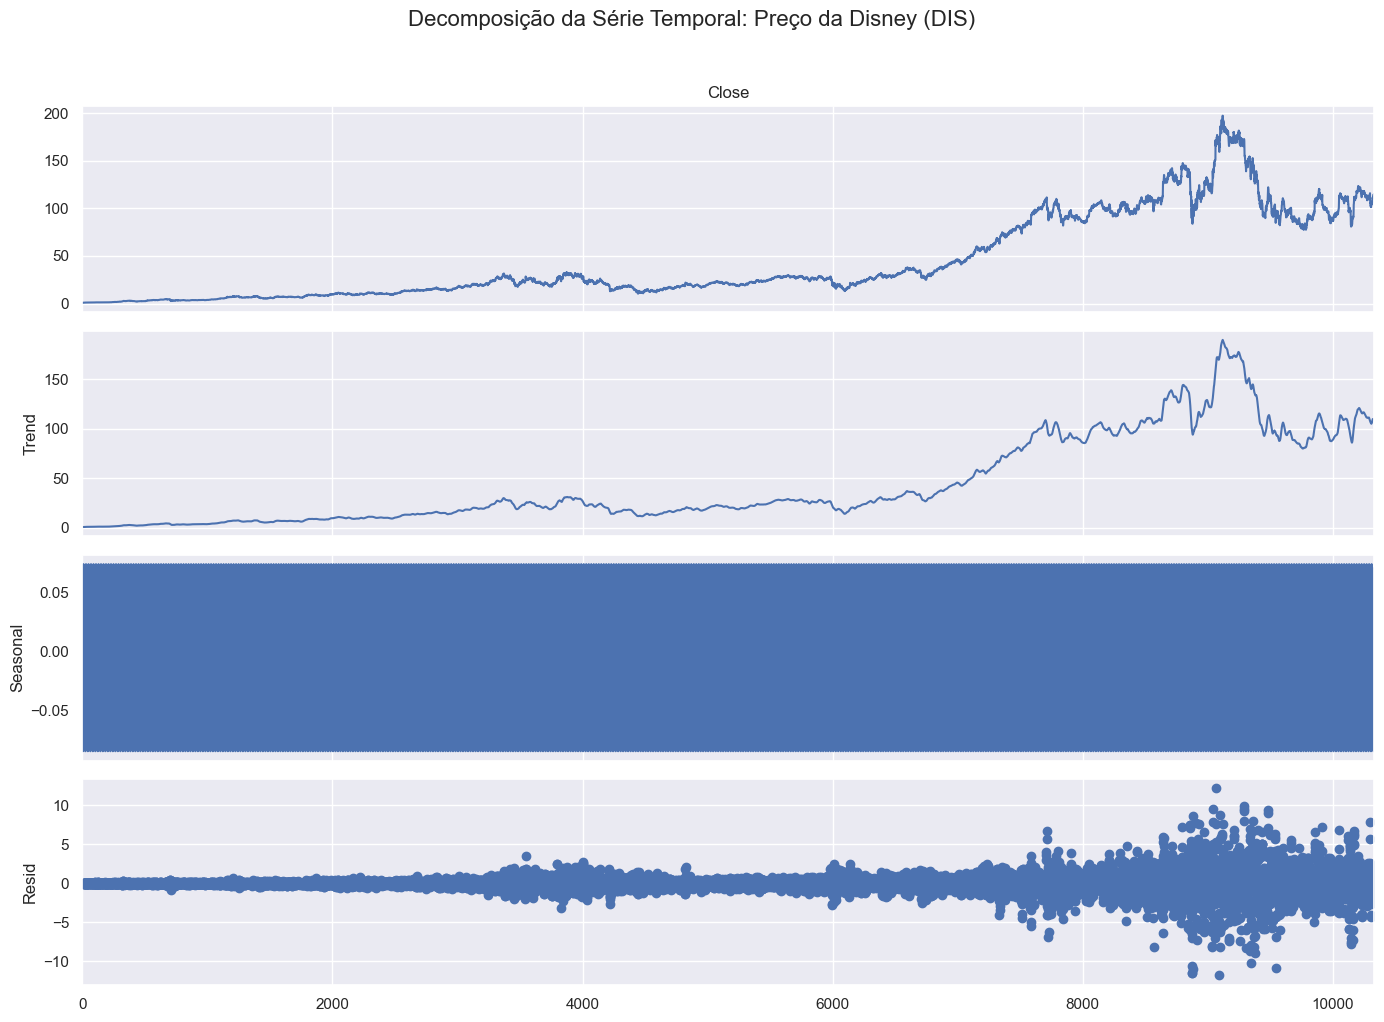

In [40]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

# Usamos period=20 porque um mês tem aproximadamente 20 a 22 dias úteis de negociação na bolsa
decomposicao = seasonal_decompose(df['Close'].dropna(), model='additive', period=20)

fig = decomposicao.plot()
fig.set_size_inches(14, 10)
plt.suptitle('Decomposição da Série Temporal: Preço da Disney (DIS)', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()